In [2]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline


from pathlib import Path

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder

In [3]:

#####################
#CONFIG
######################

NOTEBOOK_DIR = Path.cwd()

# If notebook is inside PROJECT_ROOT/notebooks:
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent

DATA_DIR = PROJECT_ROOT / "project-7-files"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
MODELS_DIR = OUTPUT_DIR / "models"

for d in (OUTPUT_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
ID_COL = "Pkey"
TARGET_COL = "target"
N_CV_FOLDS = 5

# Approximate Paris coordinates in the Lambert-93 projection (in metres).
# Used to derive a "distance to Paris" feature as a cheap proxy for
# centrality / access to the main economic hub.
PARIS_LAMBERT93_X = 652_709.0
PARIS_LAMBERT93_Y = 6_862_008.0

In [4]:
####################
#Modeling
####################

ID_COL = "Pkey"
TARGET_COL = "target"

# Columns dropped because they are either pure identifiers, free-text
# duplicates of a code already kept (Nom de la commune / du département /
# de la région), or a very-high-cardinality alternative to a coarser
# column we keep instead (INSEE_CODE -> dep/Reg/lat/long, club_federation
# -> club_category, X/Y -> distance_to_paris_km already derived from them).
DROP_COLS = [
    "INSEE_CODE",
    "Nom de la commune",
    "Nom du département",
    "Nom de la région",
    "club_federation",
    "X",
    "Y",
]

CATEGORICAL_COLS = [
    "highest_credential",
    "Job_42",
    "HOUSEHOLD",
    "Sex",
    "Act",
    "EMP_CONTRACT",
    "Eco_sect",
    "Employee_count",
    "Job_dep",
    "COMPANY_CATEGORY",
    "type_of_contract",
    "labor_force_status",
    "Job_condition",
    "Job_description_N2",
    "Job_description_N1",
    "Former_job_42",
    "FORMER_EMP_CONTRACT",
    "Eco_sect_former_job",
    "former_dep",
    "Job_dep_former_job",
    "type_of_contract_former_job",
    "labor_force_status_former_job",
    "Job_condition_former_job",
    "COMPANY_CATEGORY_former_job",
    "Employee_count_former_job",
    "Former_job_description_N2",
    "Former_job_description_N1",
    "club_category",
    "city_type",
    "dep",
    "Reg",
]

BOOLEAN_COLS = [
    "IS_STUDENT",
    "has_emp_contract",
    "has_job_detail",
    "has_retired_former",
    "has_retired_job_detail",
    "has_pension",
    "has_club",
]

NUMERIC_COLS = [
    "Age_2020",
    "PAY",
    "working_hours",
    "retirement_age",
    "working_hours_former_job",
    "retirement_pay",
    "LAT",
    "long",
    "INHABITANTS",
    "distance_to_paris_km",
    "log_inhabitants",
]

#inspect all columns in the DF and determine which feature belongs on each group
def get_feature_columns(df):
    """Restrict the column groups above to what is actually in `df`."""
    cols = set(df.columns) - {ID_COL, TARGET_COL} - set(DROP_COLS)
    categorical = [c for c in CATEGORICAL_COLS if c in cols]
    boolean = [c for c in BOOLEAN_COLS if c in cols]
    numeric = [c for c in NUMERIC_COLS if c in cols]
    known = set(categorical + boolean + numeric)
    leftover = cols - known
    if leftover:
        raise ValueError(f"Unclassified columns, update common/modeling.py: {leftover}")
    return categorical, boolean, numeric


#converts categorical columns into strings while preserving missing values.
def _stringify(X):
    """Cast every column to plain strings while preserving NaN markers.

    Some categorical columns (e.g. club_category) come out of the merges
    as floats because of upstream NaNs; mixing floats and strings in the
    same column later crashes OneHotEncoder, so we normalise everything
    to strings here, before imputation/encoding.
    """
    X = X.copy()
    for col in X.columns:
        na_mask = X[col].isna()
        X[col] = X[col].astype(str)
        X.loc[na_mask, col] = np.nan
    return X


#This function builds the preprocessing pipeline for your Random Forest model.
def random_forest_preprocessor(df):
    categorical, boolean, numeric = get_feature_columns(df)

    categorical_pipe = Pipeline(
        steps=[
            ("stringify", FunctionTransformer(_stringify, feature_names_out="one-to-one")),
            ("impute", SimpleImputer(strategy="constant", fill_value="__missing__")),
            ("encode", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    numeric_pipe = Pipeline(steps=[("impute", SimpleImputer(strategy="median"))])
    #missing values are replaced with the median of the corresponding feature.

    #Apply categrorical pipeline to categorical columns and numerical pipeline to numerical columns (and boolean too)
    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", categorical_pipe, categorical),
            ("num", numeric_pipe, numeric + boolean),
        ]
    )
    return preprocessor, categorical, boolean, numeric


def prepare_for_hgb(df):
    """Cast categorical columns to pandas 'category' dtype in place.

    HistGradientBoostingClassifier(categorical_features="from_dtype") then
    picks them up automatically, NaNs included, with no further encoding.
    """
    categorical, boolean, numeric = get_feature_columns(df)
    df = df.copy()
    for c in categorical:
        df[c] = df[c].astype("category")
    for c in boolean:
        df[c] = df[c].astype(float)
    feature_cols = categorical + boolean + numeric
    return df[feature_cols], categorical

In [5]:
######################
#Actual script
######################


POS_LABEL = "T"

#Load best parameters from random forest (script 2) and from gradient boosting (script 3)
def load_best_params(name):
    with open(OUTPUT_DIR / f"{name}_best_params.json") as f:
        return json.load(f)["best_params"]

In [6]:
#-----------------------
#Random forest
#-----------------------
def evaluate_random_forest(X, y, cv):
    #Load the optimized Random Forest hyperparameters.
    params = load_best_params("rf")
    preprocessor, *_ = random_forest_preprocessor(X)

    #Build the pipeline
    pipe = Pipeline(
        steps=[
            ("prep", preprocessor),
            (
                "model",
                RandomForestClassifier(
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                    n_estimators=params["model__n_estimators"],
                    max_depth=params["model__max_depth"],
                    min_samples_leaf=params["model__min_samples_leaf"],
                    max_features=params["model__max_features"],
                ),
            ),
        ]
    )

    #Generate out of fold predictions
    proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba", n_jobs=-1)
    #trains temporary copies of the pipeline using the cross-validation splits and generates predictions for the held-out samples.

    #Fit the pipeline on the full dataset
    pipe.fit(X, y)  # full-data fit, only used for feature importance below
    return proba, pipe


#----------------------
#Gradient boosting
#----------------------
def evaluate_hgb(X_raw, y, cv):
    #Load the optimized gradiend boosting parameters
    params = load_best_params("hgb")
    X, categorical_cols = prepare_for_hgb(X_raw)
    categorical_mask = [c in categorical_cols for c in X.columns]

    #Create the classifier
    model = HistGradientBoostingClassifier(
        categorical_features=categorical_mask,
        random_state=RANDOM_STATE,
        early_stopping=False,
        **params,
    )

    #Generate out-of-fold probabilities
    proba = cross_val_predict(model, X, y, cv=cv, method="predict_proba", n_jobs=-1)

    #Fit the model on the full dataset
    model.fit(X, y)
    return proba, model, X

In [7]:
#---------------------
#Plots of the results
#---------------------
def plot_confusion_matrix(y_true, y_pred, labels, path, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(4, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    fig.colorbar(im)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_roc(y_true, proba_pos, path, title):
    fig, ax = plt.subplots(figsize=(5, 5))
    RocCurveDisplay.from_predictions(y_true == POS_LABEL, proba_pos, ax=ax, name=title)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_feature_importance(names, importances, path, title, top_n=20):
    order = np.argsort(importances)[::-1][:top_n]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.barh(range(len(order)), importances[order][::-1])
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(np.array(names)[order][::-1])
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

In [8]:
#------------------
#Evaluation metrics
#------------------
#This function takes the actual targets and the out-of-fold probabilities and produces the model's evaluation results.
def summarize(name, y, proba, classes):
    pos_idx = list(classes).index(POS_LABEL)
    y_pred = classes[np.argmax(proba, axis=1)] #convert the probability predictions into class predictions.

    #Calculate AUC and accuracy
    auc = roc_auc_score(y == POS_LABEL, proba[:, pos_idx])
    acc = accuracy_score(y, y_pred)
    report = classification_report(y, y_pred, output_dict=True)
    
    #Show results
    print(f"\n=== {name} (out-of-fold) ===")
    print(f"ROC AUC: {auc:.4f}  Accuracy: {acc:.4f}")
    print(classification_report(y, y_pred))

    #Plot results
    plot_confusion_matrix(
        y, y_pred, classes, FIGURES_DIR / f"{name}_confusion_matrix.png", f"{name} - confusion matrix"
    )
    plot_roc(y, proba[:, pos_idx], FIGURES_DIR / f"{name}_roc_curve.png", f"{name} - ROC curve")
    return {"roc_auc": auc, "accuracy": acc, "classification_report": report}, y_pred

In [9]:
#define main script
def main():
    #Load dataset (X and Y)
    learn = pd.read_parquet(OUTPUT_DIR / "learn_features.parquet")
    y = learn[TARGET_COL]
    X = learn.drop(columns=[TARGET_COL])

    #Cross validation
    cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    #Train and evaluate the Random forest
    rf_proba, rf_pipe = evaluate_random_forest(X, y, cv)
    rf_metrics, rf_pred = summarize("random_forest", y, rf_proba, rf_pipe.classes_)

    #Train and evaluate the gradient boosting
    hgb_proba, hgb_model, X_hgb = evaluate_hgb(X, y, cv)
    hgb_metrics, hgb_pred = summarize("hist_gradient_boosting", y, hgb_proba, hgb_model.classes_)

    # --- feature importance -------------------------------------------------
    #Random forest feature importance
    rf_names = rf_pipe.named_steps["prep"].get_feature_names_out()
    rf_importance = rf_pipe.named_steps["model"].feature_importances_
    plot_feature_importance(
        rf_names, rf_importance, FIGURES_DIR / "random_forest_feature_importance.png",
        "Random forest - feature importance (impurity)",
    )

    #Gradient boosting permutation importance
    perm = permutation_importance(
        hgb_model, X_hgb, y, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
    )
    plot_feature_importance(
        X_hgb.columns, perm.importances_mean, FIGURES_DIR / "hgb_feature_importance.png",
        "Gradient boosting - permutation importance (ROC AUC)",
    )

    # --- error analysis: biggest misclassifications of the winning model ---
    winner = "random_forest" if rf_metrics["roc_auc"] >= hgb_metrics["roc_auc"] else "hist_gradient_boosting"

    #Get winning model predictions
    proba, pred = (rf_proba, rf_pred) if winner == "random_forest" else (hgb_proba, hgb_pred)
    classes = rf_pipe.classes_ if winner == "random_forest" else hgb_model.classes_
    pos_idx = list(classes).index(POS_LABEL)

    #Calculate predictions confidence
    confidence = np.abs(proba[:, pos_idx] - 0.5)

    #Identify missclased observations
    errors = X.assign(
        Pkey=learn["Pkey"], true_target=y, predicted=pred, predicted_proba_T=proba[:, pos_idx]
    )[pred != y].assign(confidence=confidence[pred != y])

    #Save the 50 biggest errors (more confident about being errors)
    errors.sort_values("confidence", ascending=False).head(50).to_csv(
        OUTPUT_DIR / "top_misclassifications.csv", index=False
    )

    #Save model and metrics
    with open(OUTPUT_DIR / "model_evaluation.json", "w") as f:
        json.dump({"random_forest": rf_metrics, "hist_gradient_boosting": hgb_metrics}, f, indent=2)

    with open(OUTPUT_DIR / "model_selection.json", "w") as f:
        json.dump({"winner": winner}, f, indent=2)

    print(f"\nSelected model: {winner}")




In [10]:
#Execute main script
if __name__ == "__main__":
    main()



=== random_forest (out-of-fold) ===
ROC AUC: 0.7937  Accuracy: 0.7265
              precision    recall  f1-score   support

           I       0.71      0.85      0.77     27702
           T       0.75      0.58      0.65     22344

    accuracy                           0.73     50046
   macro avg       0.73      0.71      0.71     50046
weighted avg       0.73      0.73      0.72     50046


=== hist_gradient_boosting (out-of-fold) ===
ROC AUC: 0.7903  Accuracy: 0.7264
              precision    recall  f1-score   support

           I       0.72      0.83      0.77     27702
           T       0.74      0.60      0.66     22344

    accuracy                           0.73     50046
   macro avg       0.73      0.71      0.72     50046
weighted avg       0.73      0.73      0.72     50046


Selected model: random_forest


## [ADDED BY CLAUDE] Expected quality of the predictions on new data

The assignment asks for *"an explicit estimate of the expected quality of the predictions on new data, in a suitable form (e.g. R² and mean squared error for regression problems)"*.

**R² and MSE are regression metrics.** Our target is a **class** (I / T), so the equivalent indicators for classification are:

| Metric | What it measures | Reference values |
|---|---|---|
| **Accuracy** | % of correctly classified people | the "always predict I" baseline gets 55.4% |
| **Balanced accuracy** | mean of the recall of I and the recall of T (corrects for the 55/45 imbalance) | 50% = random |
| **ROC AUC** | probability that a random T gets a higher score than a random I (ranking quality, independent of the threshold) | 0.5 = random, 1 = perfect |
| **F1 (class T)** | harmonic mean of precision and recall for class T | |
| **Brier score** | **the mean squared error of the predicted probabilities**: mean of (p̂(T) − 1{y=T})². This is literally the MSE, applied to a classifier | 0 = perfect, 0.247 = always predicting the class proportions |
| **Brier skill score** | 1 − Brier(model) / Brier(baseline). It plays the role of **R²**: the share of the baseline's squared error that the model removes | 0 = no better than the baseline, 1 = perfect |
| **Log loss** | penalises confident wrong predictions | 0.687 = baseline |

**How the estimate is obtained:** 5-fold stratified cross-validation. In each fold the model is trained on 80% of the learn set and scored on the remaining 20%, which it has never seen. That 20% plays the role of "new data". The mean over the 5 folds is the expected quality, and the standard deviation shows how stable it is. A `DummyClassifier` (always predicts the class proportions) is evaluated the same way as a reference.

*Caveat:* the hyperparameters were chosen with the same CV splits, so these numbers are very slightly optimistic. With few configurations tried and very close scores, this bias is small (well below 1 AUC point). A fully unbiased estimate would need nested CV or a held-out set never used for tuning.

In [ ]:
# [ADDED BY CLAUDE] Per-fold quality metrics for both models + a baseline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, brier_score_loss, f1_score, log_loss, matthews_corrcoef


def quality_metrics(y_true, proba_T, prior_T):
    """All metrics for one fold. proba_T = predicted probability of class T."""
    y_T = (y_true == POS_LABEL).astype(int)
    y_pred = np.where(proba_T >= 0.5, POS_LABEL, "I")
    brier = brier_score_loss(y_T, proba_T)
    brier_ref = brier_score_loss(y_T, np.full(len(y_T), prior_T))  # always predict the training-fold proportion
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_T, proba_T) if len(np.unique(proba_T)) > 1 else 0.5,
        "f1_T": f1_score(y_true, y_pred, pos_label=POS_LABEL, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "brier_score (MSE of probabilities)": brier,
        "brier_skill_score (R2-like)": 1 - brier / brier_ref,
        "log_loss": log_loss(y_T, np.clip(proba_T, 1e-15, 1 - 1e-15)),
    }


def cross_validated_quality(make_estimator, X, y, cv):
    """Train on k-1 folds, score on the held-out fold. Returns per-fold metrics and out-of-fold probabilities."""
    rows, oof = [], np.zeros(len(y))
    for fold, (tr, va) in enumerate(cv.split(X, y), start=1):
        est = make_estimator()
        est.fit(X.iloc[tr], y.iloc[tr])
        proba_T = est.predict_proba(X.iloc[va])[:, list(est.classes_).index(POS_LABEL)]
        oof[va] = proba_T
        prior_T = (y.iloc[tr] == POS_LABEL).mean()
        rows.append({"fold": fold, **quality_metrics(y.iloc[va].to_numpy(), proba_T, prior_T)})
    return pd.DataFrame(rows).set_index("fold"), oof


learn = pd.read_parquet(OUTPUT_DIR / "learn_features.parquet")
y = learn[TARGET_COL]
X = learn.drop(columns=[TARGET_COL])
cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Same estimators as in evaluate_random_forest / evaluate_hgb above
rf_params = load_best_params("rf")
rf_preprocessor, *_ = random_forest_preprocessor(X)
make_rf = lambda: Pipeline(steps=[
    ("prep", clone(rf_preprocessor)),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE, n_jobs=-1,
        n_estimators=rf_params["model__n_estimators"],
        max_depth=rf_params["model__max_depth"],
        min_samples_leaf=rf_params["model__min_samples_leaf"],
        max_features=rf_params["model__max_features"],
    )),
])

hgb_params = load_best_params("hgb")
X_hgb, hgb_categorical = prepare_for_hgb(X)
hgb_mask = [c in hgb_categorical for c in X_hgb.columns]
make_hgb = lambda: HistGradientBoostingClassifier(
    categorical_features=hgb_mask, random_state=RANDOM_STATE, early_stopping=False, **hgb_params
)

make_dummy = lambda: DummyClassifier(strategy="prior")

per_fold = {}
oof_proba = {}
per_fold["baseline (class proportions)"], oof_proba["baseline"] = cross_validated_quality(make_dummy, X, y, cv)
per_fold["random_forest"], oof_proba["random_forest"] = cross_validated_quality(make_rf, X, y, cv)
per_fold["hist_gradient_boosting"], oof_proba["hist_gradient_boosting"] = cross_validated_quality(make_hgb, X_hgb, y, cv)

for name, df_folds in per_fold.items():
    print(f"\n=== {name}: metrics on each held-out fold ===")
    display(df_folds.round(4))



=== baseline (class proportions): metrics on each held-out fold ===


,accuracy,balanced_accuracy,roc_auc,f1_T,mcc,brier_score (MSE of probabilities),brier_skill_score (R2-like),log_loss
fold,,,,,,,,
1,0.5535,0.5,0.5,0.0,0.0,0.2471,0.0,0.6874
2,0.5536,0.5,0.5,0.0,0.0,0.2471,0.0,0.6874
3,0.5535,0.5,0.5,0.0,0.0,0.2471,0.0,0.6874
4,0.5535,0.5,0.5,0.0,0.0,0.2471,0.0,0.6874
5,0.5535,0.5,0.5,0.0,0.0,0.2471,0.0,0.6874



=== random_forest: metrics on each held-out fold ===


,accuracy,balanced_accuracy,roc_auc,f1_T,mcc,brier_score (MSE of probabilities),brier_skill_score (R2-like),log_loss
fold,,,,,,,,
1,0.7288,0.7136,0.7981,0.6529,0.4498,0.1813,0.2664,0.5406
2,0.7236,0.7096,0.7882,0.6515,0.4379,0.1845,0.2532,0.5481
3,0.7252,0.7099,0.7930,0.6482,0.4424,0.1823,0.2624,0.5411
4,0.7285,0.7151,0.7925,0.6596,0.4480,0.1830,0.2597,0.5444
5,0.7262,0.7120,0.7969,0.6539,0.4436,0.1819,0.2641,0.5411



=== hist_gradient_boosting: metrics on each held-out fold ===


,accuracy,balanced_accuracy,roc_auc,f1_T,mcc,brier_score (MSE of probabilities),brier_skill_score (R2-like),log_loss
fold,,,,,,,,
1,0.7283,0.7154,0.7938,0.6615,0.4471,0.1818,0.2644,0.5404
2,0.7230,0.7110,0.7855,0.6587,0.4358,0.1846,0.2530,0.5472
3,0.7203,0.7070,0.7900,0.6505,0.4304,0.1829,0.2601,0.5419
4,0.7286,0.7169,0.7879,0.6664,0.4474,0.1835,0.2573,0.5451
5,0.7315,0.7195,0.7948,0.6686,0.4536,0.1813,0.2664,0.5398


In [ ]:
# [ADDED BY CLAUDE] Summary table: expected quality on new data = mean ± std over the 5 held-out folds
summary = pd.concat(
    {name: df_folds.agg(["mean", "std"]).T for name, df_folds in per_fold.items()}, axis=1
)
summary_str = pd.DataFrame({
    name: [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary[(name, "mean")], summary[(name, "std")])]
    for name in per_fold
}, index=summary.index)
display(summary_str)

with open(OUTPUT_DIR / "prediction_quality.json", "w") as f:
    json.dump(
        {name: {m: {"mean": float(summary.loc[m, (name, "mean")]), "std": float(summary.loc[m, (name, "std")])}
                for m in summary.index} for name in per_fold},
        f, indent=2,
    )
print("Saved to", OUTPUT_DIR / "prediction_quality.json")


,baseline (class proportions),random_forest,hist_gradient_boosting
accuracy,0.5535 ± 0.0000,0.7265 ± 0.0022,0.7264 ± 0.0046
balanced_accuracy,0.5000 ± 0.0000,0.7120 ± 0.0023,0.7139 ± 0.0050
roc_auc,0.5000 ± 0.0000,0.7937 ± 0.0039,0.7904 ± 0.0039
f1_T,0.0000 ± 0.0000,0.6532 ± 0.0042,0.6612 ± 0.0071
mcc,0.0000 ± 0.0000,0.4444 ± 0.0047,0.4428 ± 0.0095
brier_score (MSE of probabilities),0.2471 ± 0.0000,0.1826 ± 0.0013,0.1828 ± 0.0013
brier_skill_score (R2-like),0.0000 ± 0.0000,0.2612 ± 0.0051,0.2603 ± 0.0054
log_loss,0.6874 ± 0.0000,0.5431 ± 0.0032,0.5429 ± 0.0032


Saved to /home/jlopez/github/Dauphine/machine_learning/project/outputs/prediction_quality.json


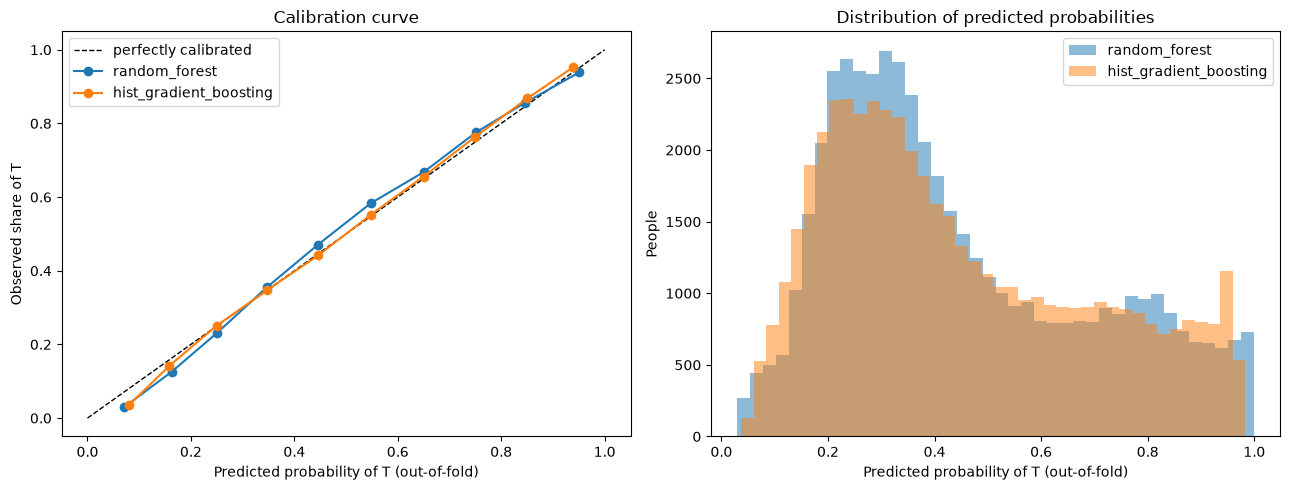

In [ ]:
# [ADDED BY CLAUDE] Calibration: when the model says "70% T", is it right ~70% of the time?
# This checks whether the predicted probabilities can be trusted, not only the predicted class.
from sklearn.calibration import calibration_curve

y_T = (y == POS_LABEL).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
for name in ["random_forest", "hist_gradient_boosting"]:
    frac_pos, mean_pred = calibration_curve(y_T, oof_proba[name], n_bins=10)
    axes[0].plot(mean_pred, frac_pos, marker="o", label=name)
    axes[1].hist(oof_proba[name], bins=40, alpha=0.5, label=name)
axes[0].set_xlabel("Predicted probability of T (out-of-fold)")
axes[0].set_ylabel("Observed share of T")
axes[0].set_title("Calibration curve")
axes[0].legend()
axes[1].set_xlabel("Predicted probability of T (out-of-fold)")
axes[1].set_ylabel("People")
axes[1].set_title("Distribution of predicted probabilities")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "calibration_curve.png", dpi=150)
plt.show()


### [ADDED BY CLAUDE] Conclusion: expected quality on new data

| (mean ± std over 5 held-out folds) | Baseline | Random forest (selected) | Gradient boosting |
|---|---|---|---|
| Accuracy | 0.554 | **0.727 ± 0.002** | 0.726 ± 0.005 |
| Balanced accuracy | 0.500 | 0.712 ± 0.002 | 0.714 ± 0.005 |
| ROC AUC | 0.500 | **0.794 ± 0.004** | 0.790 ± 0.004 |
| F1 (T) | 0 | 0.653 ± 0.004 | 0.661 ± 0.007 |
| Brier score (= MSE of probabilities) | 0.247 | **0.183 ± 0.001** | 0.183 ± 0.001 |
| Brier skill score (R²-like) | 0 | **0.261 ± 0.005** | 0.260 ± 0.005 |
| Log loss | 0.687 | 0.543 ± 0.003 | 0.543 ± 0.003 |

* On new data drawn from the same population, the selected random forest should classify **about 72–73% of people correctly** (vs 55% when always predicting "I"), with a ROC AUC of **≈0.79**.
* In MSE / R² terms, the mean squared error of the predicted probabilities falls from 0.247 to 0.183. The model removes **≈26% of the squared error** of the baseline (Brier skill score, the classification analogue of R²).
* The estimates are **stable**: the standard deviation across folds is at most 0.5 points for accuracy and 0.4 points for AUC. Since the learn and test sets have the same distributions (KS tests in notebook 1) and the same missingness structure, performance on `test_dataset` should be similar.
* The **calibration curve** is close to the diagonal for both models, so the predicted probabilities can be read as real probabilities (e.g. among people with p(T) ≈ 0.7, about 70% are T).
* The two models are statistically indistinguishable: all their differences are within one standard deviation.